# Used Cars: Price Analysis & Prediction

**Goal:** understand what drives the selling price of used cars and build a model that predicts it.

**Data:** 8,128 listings with `brand`, `km_driven`, `fuel`, `owner`, `selling_price`.

## Key findings
*(filled in at the end of the notebook, see "Conclusions")*


## 1. Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

raw = pd.read_csv("data/cars_dataset.csv")
print(raw.shape)
raw.head()

(8128, 5)


,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000


In [2]:
raw.info()
print("\nMissing values:\n", raw.isna().sum())
print("\nDuplicate rows:", raw.duplicated().sum(), f"({raw.duplicated().mean():.1%})")
print("\nOwner categories:\n", raw["owner"].value_counts())
print("\nFuel categories:\n", raw["fuel"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   brand          8128 non-null   str  
 1   km_driven      8128 non-null   int64
 2   fuel           8128 non-null   str  
 3   owner          8128 non-null   str  
 4   selling_price  8128 non-null   int64
dtypes: int64(2), str(3)
memory usage: 317.6 KB

Missing values:
 brand            0
km_driven        0
fuel             0
owner            0
selling_price    0
dtype: int64

Duplicate rows: 1678 (20.6%)

Owner categories:
 owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64

Fuel categories:
 fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64


## 2. Data cleaning

Decisions (each one is justified, not applied blindly):

1. **Drop exact duplicate rows**: about 20% of the data. They inflate some cars and bias every statistic. Caveat: with only five columns left, some identical rows could be genuinely different cars; section 5 checks that the conclusions do not depend on this choice.
2. **Drop `Test Drive Car`** (5 rows): a different kind of listing, with a median price around 5.9M that would distort any owner analysis.
3. **Remove implausible mileage** (`km_driven < 100` or `> 500,000`): likely data-entry errors.
4. **Keep expensive cars.** Luxury brands (Audi, Mercedes, ...) are real, not errors. Instead of deleting or clipping them, I model **log(price)**, which tames the skew.

In [3]:
df = raw.drop_duplicates().copy()
print("After dropping duplicates:", len(df))

df = df[df["owner"] != "Test Drive Car"]
print("After dropping Test Drive Car:", len(df))

bad_km = (df["km_driven"] < 100) | (df["km_driven"] > 500_000)
print("Implausible mileage rows removed:", bad_km.sum())
df = df[~bad_km].reset_index(drop=True)

df["log_price"] = np.log(df["selling_price"])
print("Final shape:", df.shape)
df.describe()

After dropping duplicates: 6450
After dropping Test Drive Car: 6445
Implausible mileage rows removed: 4
Final shape: (6441, 6)


,km_driven,selling_price,log_price
count,6441.000000,6.441000e+03,6441.000000
mean,73872.705170,5.213181e+05,12.868495
std,48895.681872,5.196618e+05,0.770045
min,1000.000000,2.999900e+04,10.308919
25%,39414.000000,2.500000e+05,12.429216
50%,70000.000000,4.099990e+05,12.923910
75%,100000.000000,6.400000e+05,13.369223
max,500000.000000,1.000000e+07,16.118096


## 3. Exploratory analysis

### 3.1 Distributions: raw vs log scale

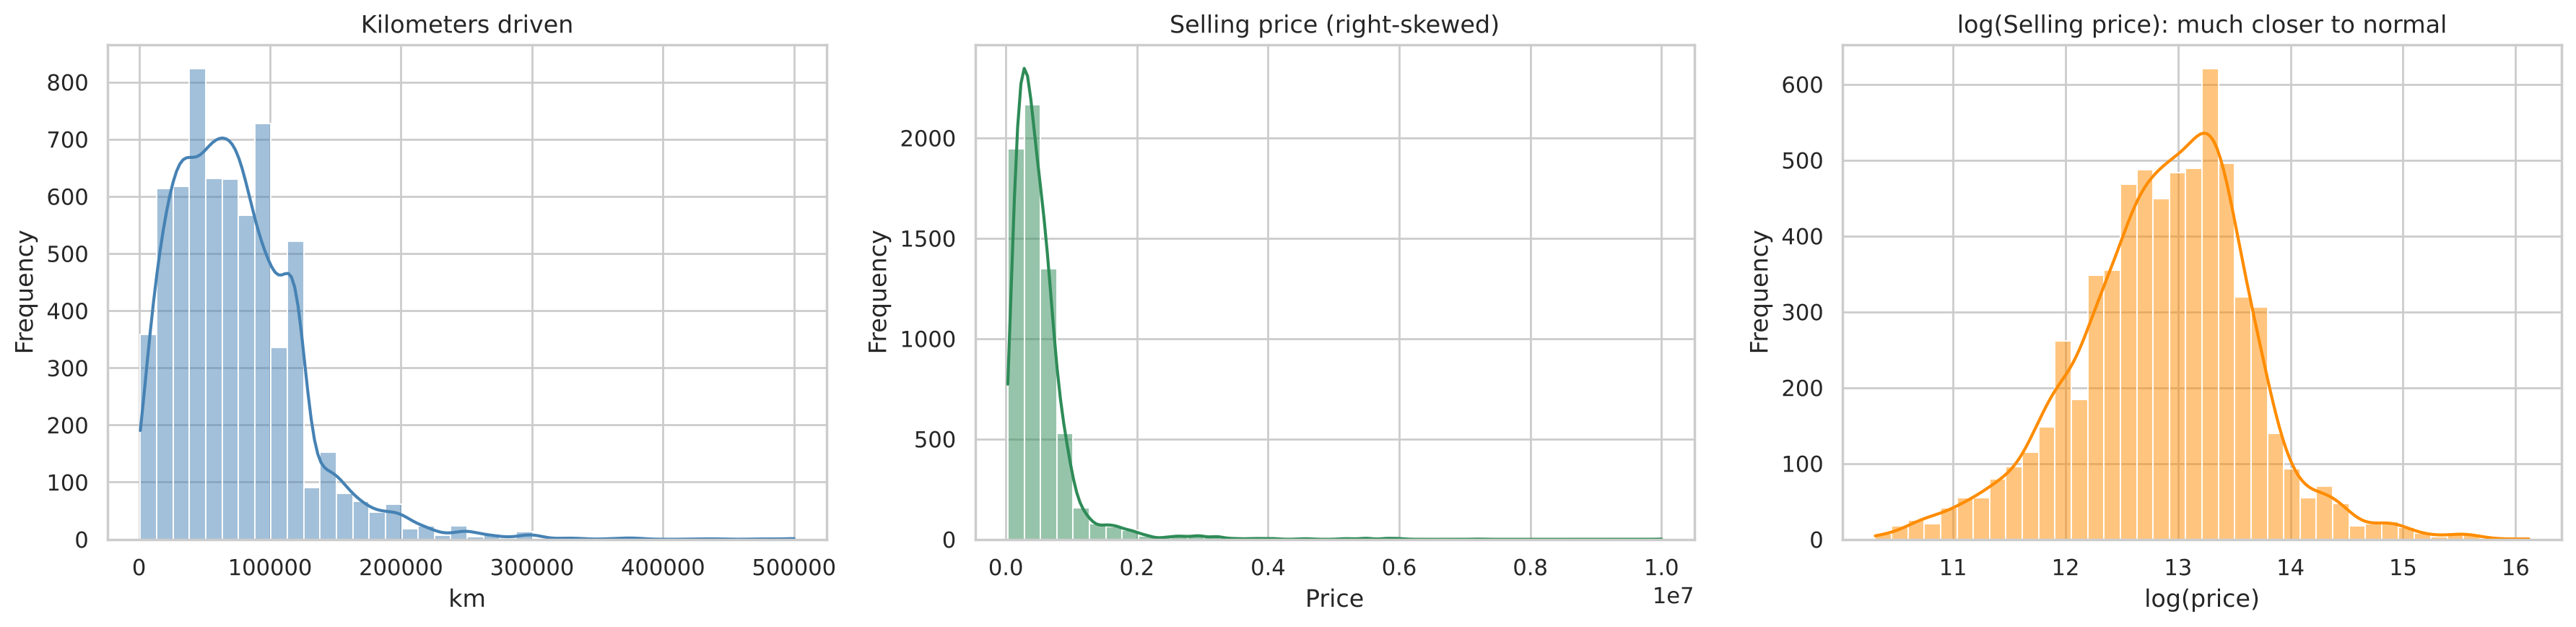

Skewness price: 5.35 | log price: -0.17


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(df["km_driven"], bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set(title="Kilometers driven", xlabel="km", ylabel="Frequency")
sns.histplot(df["selling_price"], bins=40, kde=True, ax=axes[1], color="seagreen")
axes[1].set(title="Selling price (right-skewed)", xlabel="Price", ylabel="Frequency")
sns.histplot(df["log_price"], bins=40, kde=True, ax=axes[2], color="darkorange")
axes[2].set(title="log(Selling price): much closer to normal", xlabel="log(price)", ylabel="Frequency")
plt.tight_layout(); plt.show()

print("Skewness price:", round(df["selling_price"].skew(), 2), "| log price:", round(df["log_price"].skew(), 2))

### 3.2 Price by brand, fuel and number of owners

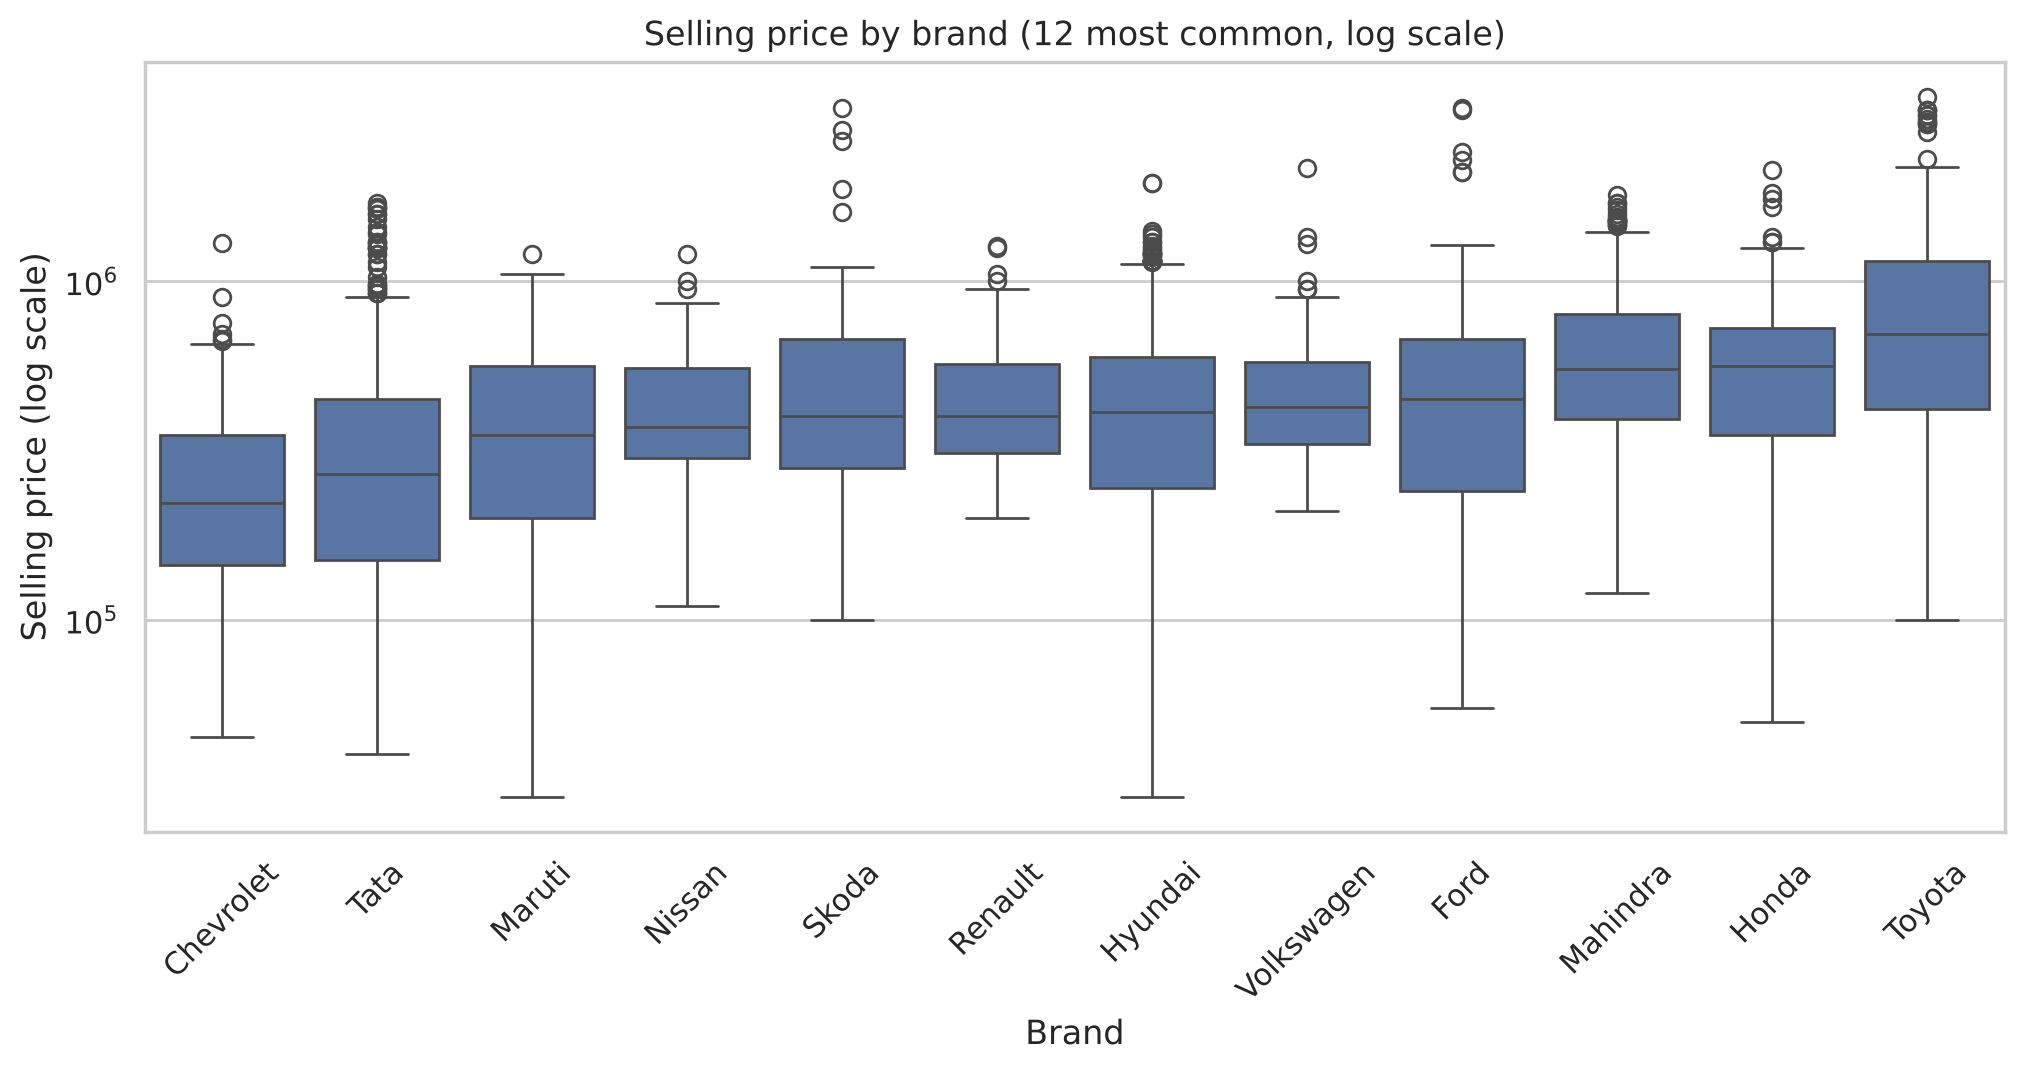

In [5]:
top_brands = df["brand"].value_counts().head(12).index
order = df[df["brand"].isin(top_brands)].groupby("brand")["selling_price"].median().sort_values().index

plt.figure(figsize=(12, 5))
sns.boxplot(data=df[df["brand"].isin(top_brands)], x="brand", y="selling_price", order=order)
plt.yscale("log"); plt.xticks(rotation=45)
plt.title("Selling price by brand (12 most common, log scale)")
plt.ylabel("Selling price (log scale)"); plt.xlabel("Brand"); plt.show()

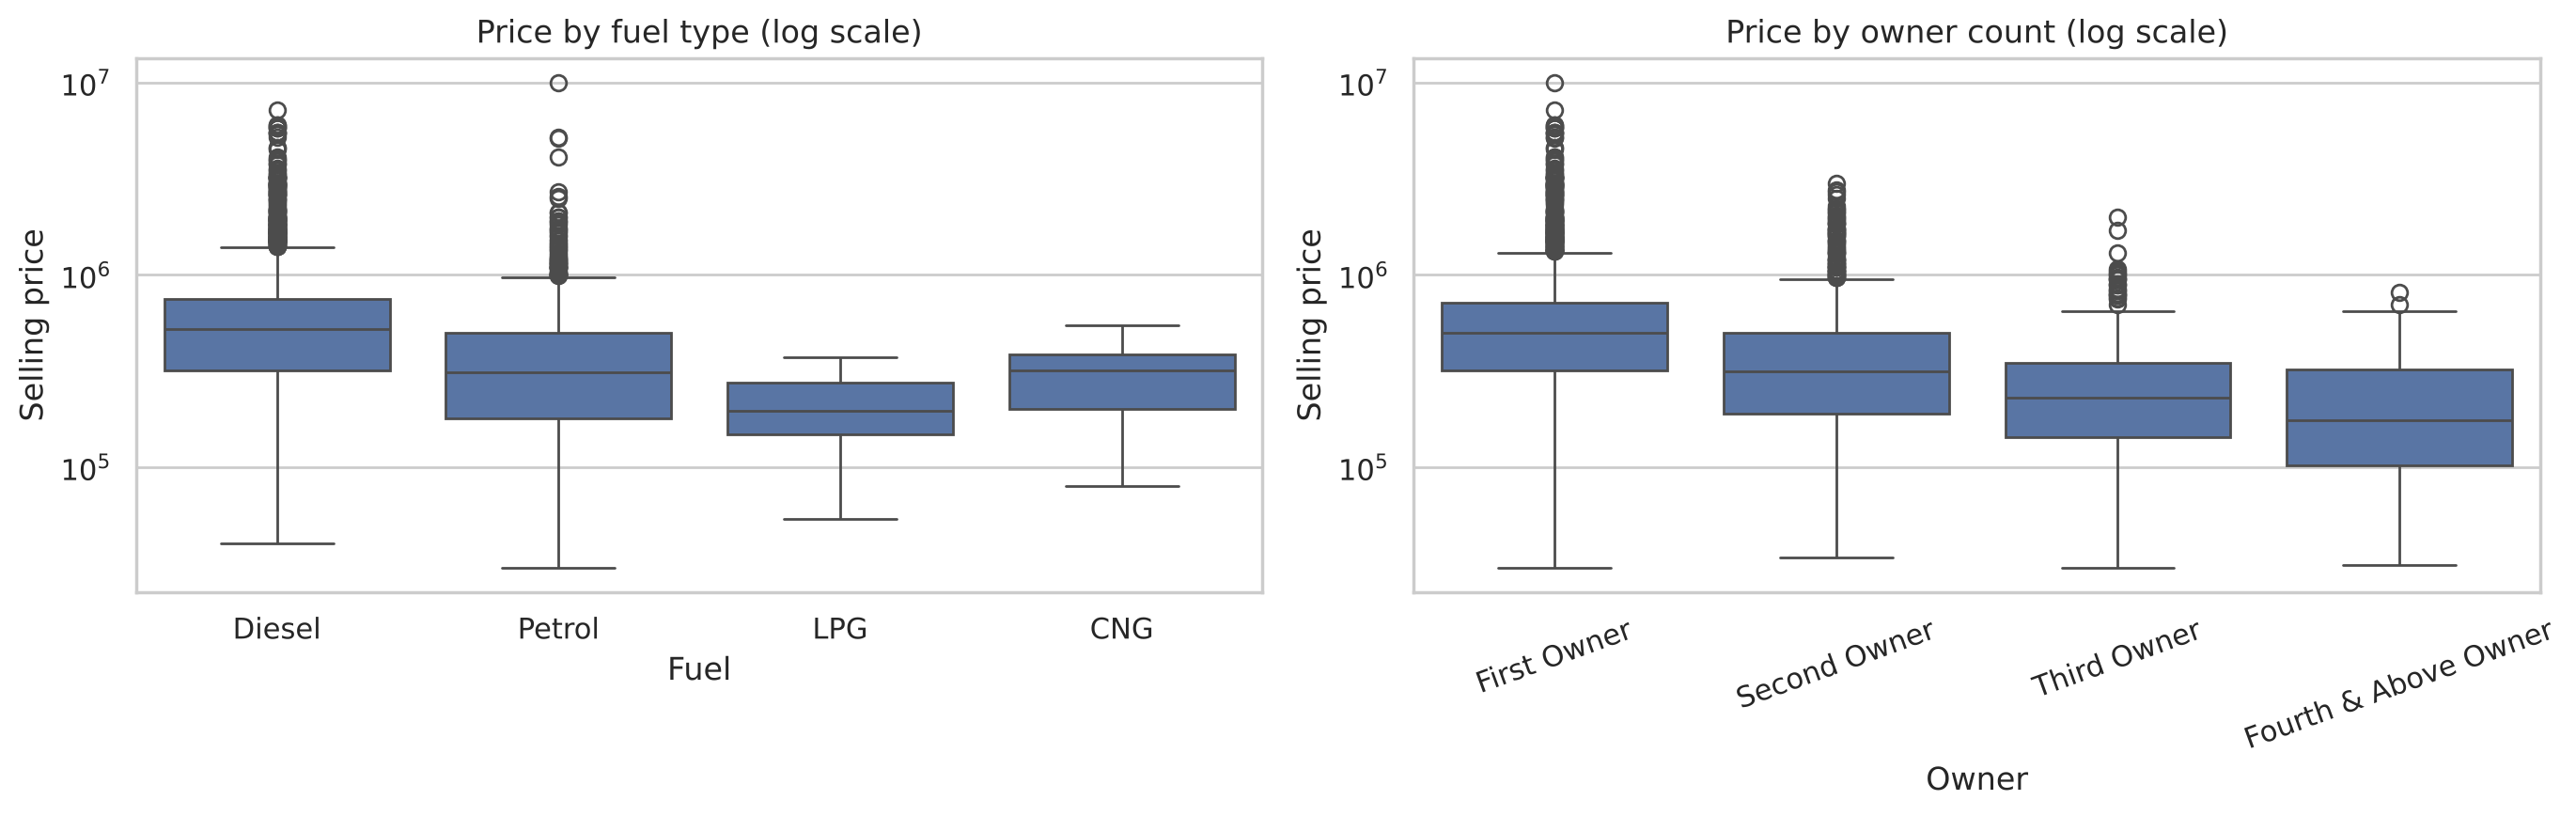

,count,median
fuel,,
CNG,54,320000.0
Diesel,3517,520000.0
LPG,38,195500.0
Petrol,2832,310000.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="fuel", y="selling_price", ax=axes[0]); axes[0].set_yscale("log")
axes[0].set(title="Price by fuel type (log scale)", ylabel="Selling price", xlabel="Fuel")
owner_order = ["First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]
sns.boxplot(data=df, x="owner", y="selling_price", order=owner_order, ax=axes[1]); axes[1].set_yscale("log")
axes[1].set(title="Price by owner count (log scale)", ylabel="Selling price", xlabel="Owner")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

df.groupby("fuel")["selling_price"].agg(["count", "median"]).round(0)

## 4. Mileage vs price

Both variables are skewed, so I use **Spearman** (rank) correlation instead of Pearson. For each fuel type I also report the **sample size** and a **95% confidence interval**, because LPG and CNG have very few cars and their coefficients are much less reliable.

In [7]:
def spearman_ci(x, y, alpha=0.05):
    r, p = stats.spearmanr(x, y)
    n = len(x)
    z = np.arctanh(r); se = 1.06 / np.sqrt(n - 3)  # Fieller approximation for Spearman
    lo, hi = np.tanh(z - stats.norm.ppf(1 - alpha / 2) * se), np.tanh(z + stats.norm.ppf(1 - alpha / 2) * se)
    return r, lo, hi, p, n

rows = []
for fuel, g in df.groupby("fuel"):
    r, lo, hi, p, n = spearman_ci(g["km_driven"], g["selling_price"])
    rows.append({"fuel": fuel, "n": n, "spearman_r": r, "ci_low": lo, "ci_high": hi, "p_value": p})
corr_table = pd.DataFrame(rows).sort_values("n", ascending=False).round(3)
corr_table

,fuel,n,spearman_r,ci_low,ci_high,p_value
1,Diesel,3517,-0.440,-0.467,-0.411,0.000
3,Petrol,2832,-0.544,-0.571,-0.516,0.000
0,CNG,54,-0.588,-0.747,-0.365,0.000
2,LPG,38,-0.425,-0.667,-0.102,0.008


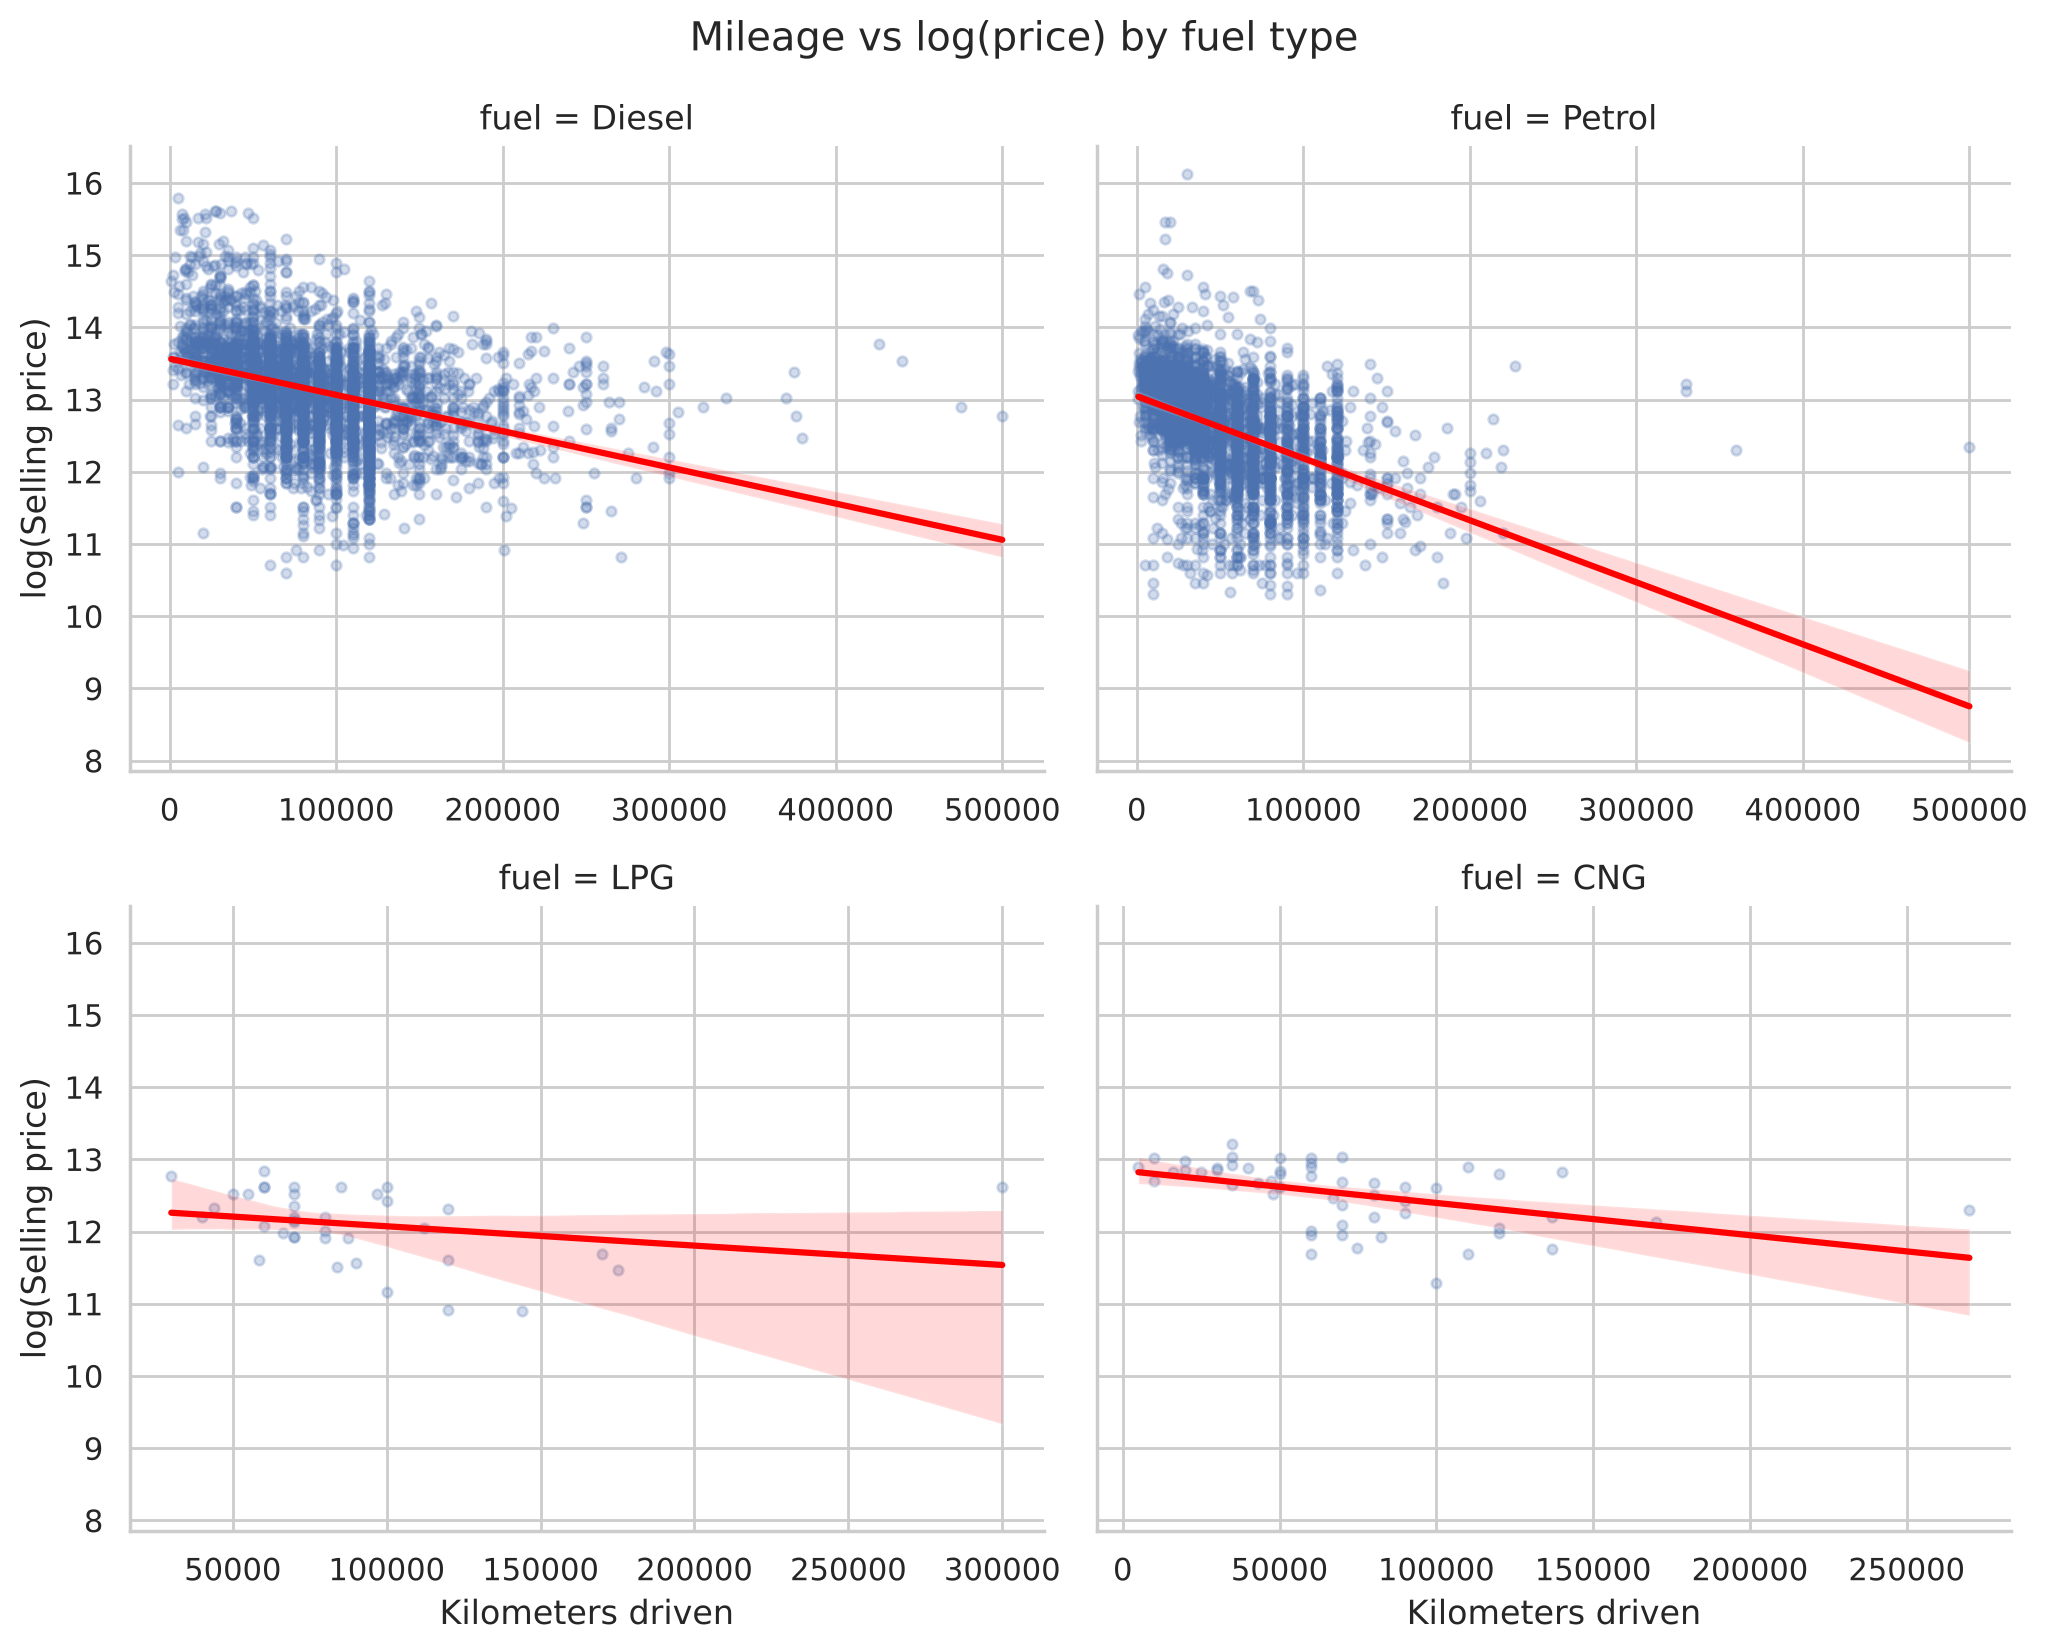

In [8]:
g = sns.lmplot(data=df, x="km_driven", y="log_price", col="fuel", col_wrap=2, height=4, aspect=1.3,
               scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "red"}, facet_kws={"sharex": False, "sharey": True})
g.set_axis_labels("Kilometers driven", "log(Selling price)")
g.fig.suptitle("Mileage vs log(price) by fuel type", y=1.03); plt.show()

## 5. Predictive model

Target: `log(selling_price)`. Features: `brand`, `km_driven`, `fuel`, `owner`.
I compare a linear baseline against tree ensembles using 5-fold cross-validation on the training set, then evaluate once on a held-out test set.

In [9]:
features = ["brand", "km_driven", "fuel", "owner"]
X, y = df[features], df["log_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["brand", "fuel", "owner"]),
    ("num", StandardScaler(), ["km_driven"]),   # scaling matters for the linear model
])

models = {
    "Ridge (baseline)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results = []
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)])
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")
    results.append({"model": name, "cv_r2_mean": cv.mean(), "cv_r2_std": cv.std()})
pd.DataFrame(results).round(3)

,model,cv_r2_mean,cv_r2_std
0,Ridge (baseline),0.530,0.025
1,Random Forest,0.493,0.017
2,Gradient Boosting,0.558,0.020


Test R² (log scale):          0.562
Test MAE (original currency): 186,680
Median absolute % error:      28.5%


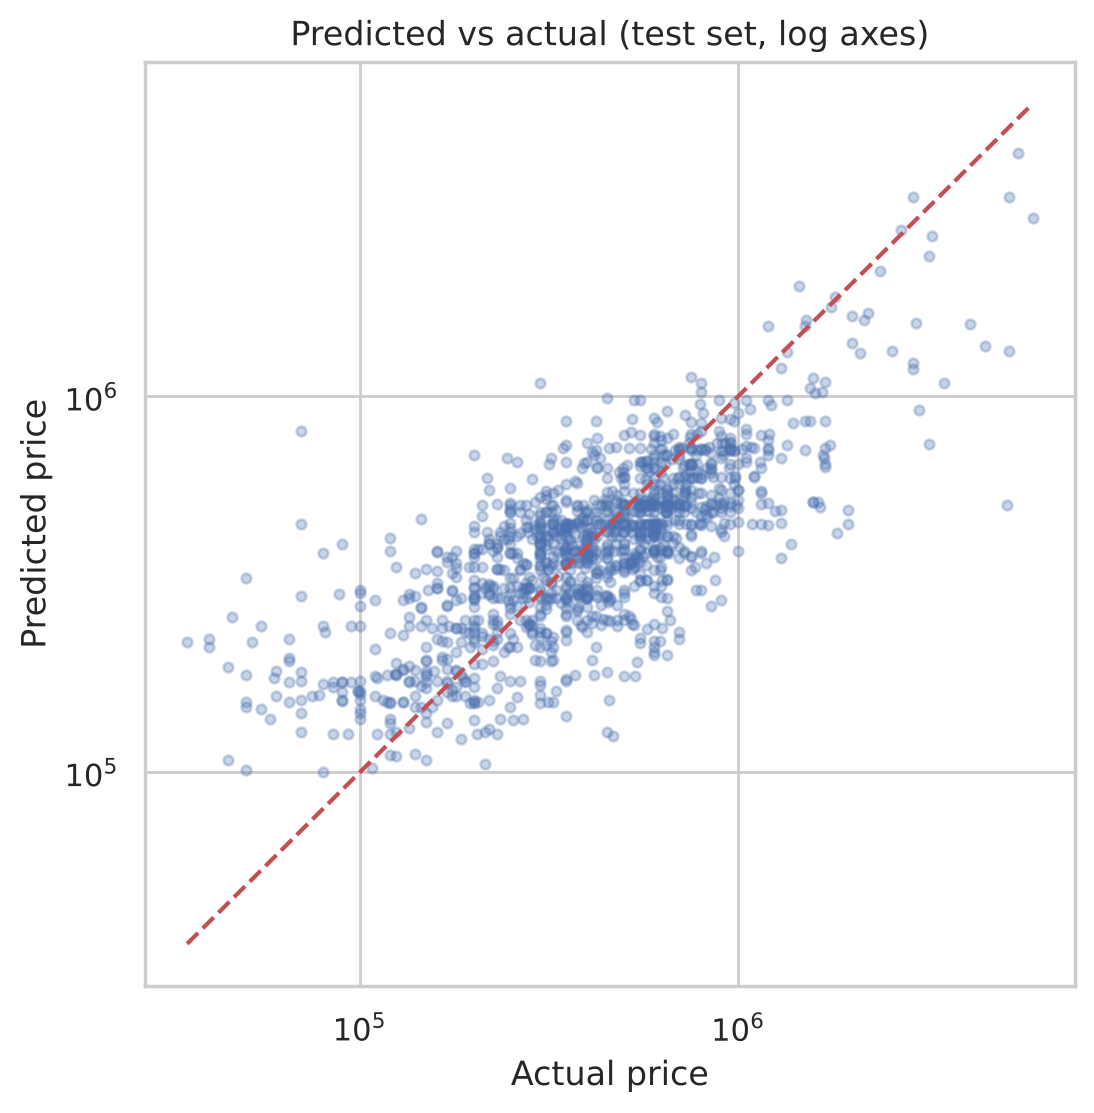

In [10]:
best = Pipeline([("pre", pre), ("model", models["Gradient Boosting"])]).fit(X_train, y_train)
pred_log = best.predict(X_test)
pred, actual = np.exp(pred_log), np.exp(y_test)

print(f"Test R² (log scale):          {r2_score(y_test, pred_log):.3f}")
print(f"Test MAE (original currency): {mean_absolute_error(actual, pred):,.0f}")
print(f"Median absolute % error:      {np.median(np.abs(pred - actual) / actual):.1%}")

plt.figure(figsize=(6, 6))
plt.scatter(actual, pred, alpha=0.3, s=12)
lims = [actual.min(), actual.max()]
plt.plot(lims, lims, "r--"); plt.xscale("log"); plt.yscale("log")
plt.xlabel("Actual price"); plt.ylabel("Predicted price"); plt.title("Predicted vs actual (test set, log axes)")
plt.show()

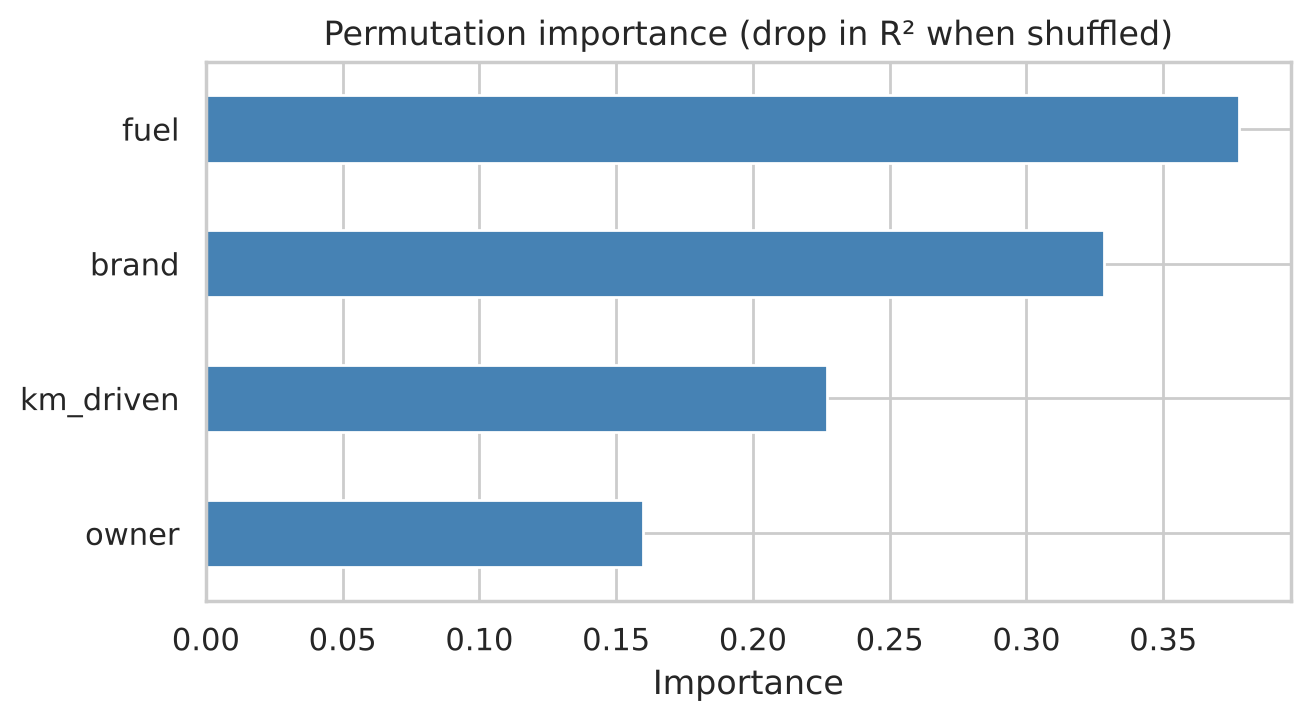

In [11]:
imp = permutation_importance(best, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.Series(imp.importances_mean, index=features).sort_values()
imp_df.plot.barh(figsize=(7, 3.5), color="steelblue")
plt.title("Permutation importance (drop in R² when shuffled)"); plt.xlabel("Importance"); plt.show()

### Sanity checks a reviewer would ask for

1. Is the model better than a trivial baseline (predict the median price of the car's brand)?
2. Exp of a log-price prediction estimates the **median**, not the mean price: how large is that bias?
3. Is the error similar for cheap and expensive cars?

In [12]:
brand_med = X_train.assign(y=y_train).groupby("brand")["y"].median()
base_pred = X_test["brand"].map(brand_med).fillna(y_train.median())
base_r2 = r2_score(y_test, base_pred)
print(f"Baseline 'brand median' R²: {base_r2:.3f}  vs  Gradient Boosting R²: {r2_score(y_test, pred_log):.3f}")
print(f"mean(predicted price) / mean(actual price) = {pred.mean() / actual.mean():.2f}  (median-type predictions: fine for MAE, biased low for totals)")

terc = pd.qcut(pred, 3, labels=["low", "mid", "high"])
pd.DataFrame({"MAE": [mean_absolute_error(actual[terc == t], pred[terc == t]) for t in ["low", "mid", "high"]],
              "median abs % error": [np.median(np.abs(pred[terc == t] - actual[terc == t]) / actual[terc == t]) for t in ["low", "mid", "high"]]},
             index=["predicted low", "predicted mid", "predicted high"]).round(2)

Baseline 'brand median' R²: 0.212  vs  Gradient Boosting R²: 0.562
mean(predicted price) / mean(actual price) = 0.85  (median-type predictions: fine for MAE, biased low for totals)


,MAE,median abs % error
predicted low,103900.92,0.34
predicted mid,155396.30,0.29
predicted high,306293.47,0.24


### Does removing duplicates change the conclusion?
Only five columns are available, so some identical rows may be different cars. I compare three set-ups with the same model: **(A)** deduplicated data, **(B)** duplicates kept with a random split (leaky: twins land in train and test), and **(C)** duplicates kept but **grouped**, so identical rows never sit in both train and test.

In [13]:
from sklearn.model_selection import GroupShuffleSplit
feat = ["brand", "km_driven", "fuel", "owner"]
full = raw[(raw["owner"] != "Test Drive Car") & (raw["km_driven"] >= 100) & (raw["km_driven"] <= 500_000)].reset_index(drop=True)
full["group"] = full.groupby(feat + ["selling_price"]).ngroup()

def gb_r2(tr, te):
    m = Pipeline([("pre", pre), ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))]).fit(tr[feat], np.log(tr["selling_price"]))
    return r2_score(np.log(te["selling_price"]), m.predict(te[feat]))

res = {"A. deduplicated, random split": [], "B. duplicates kept, random split (leaky)": [], "C. duplicates kept, grouped split": []}
for s in range(5):
    a, b = train_test_split(df, test_size=0.2, random_state=s); res["A. deduplicated, random split"].append(gb_r2(a, b))
    a, b = train_test_split(full, test_size=0.2, random_state=s); res["B. duplicates kept, random split (leaky)"].append(gb_r2(a, b))
    tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=s).split(full, groups=full["group"]))
    res["C. duplicates kept, grouped split"].append(gb_r2(full.iloc[tr], full.iloc[te]))
sens = pd.DataFrame({k: {"mean R²": np.mean(v), "std": np.std(v)} for k, v in res.items()}).T.round(3)
sens

,mean R²,std
"A. deduplicated, random split",0.570,0.017
"B. duplicates kept, random split (leaky)",0.666,0.011
"C. duplicates kept, grouped split",0.606,0.040


**Reading:** A and C agree (within noise), so the conclusion does not depend on the duplicate-removal choice. B is higher only because twins leak between train and test, which is exactly why duplicates must not be split randomly.

## 6. Conclusions

In [14]:
top_feat = imp_df.index[-1]
neg = corr_table[corr_table["spearman_r"] < 0]
print(f'''1. Data quality: removed {len(raw) - len(df)} rows ({(len(raw)-len(df))/len(raw):.1%}), mostly exact duplicates.
2. Higher mileage goes with lower price for every fuel type (Spearman r from {corr_table.spearman_r.min():.2f} to {corr_table.spearman_r.max():.2f}),
   but the relationship is moderate, so mileage alone does not explain price.
3. LPG/CNG results rest on only {int(corr_table.set_index("fuel").loc["LPG","n"])}/{int(corr_table.set_index("fuel").loc["CNG","n"])} cars: wide confidence intervals, so treat with caution.
4. Most influential feature in the model: '{top_feat}', followed by '{imp_df.index[-2]}'. Fuel type may be a proxy for car segment or age (cannot be verified here: there is no year or body-type column), so it should not be read as a direct cause of price.
5. Best model: Gradient Boosting, test R² = {r2_score(y_test, pred_log):.2f} (log scale), well above the brand-median baseline (R² = {base_r2:.2f}). Predictions are medians: the mean price is under-predicted by about {1 - pred.mean() / actual.mean():.0%}.
6. The R² is stable whether duplicates are removed or kept with a grouped split ({sens.iloc[0,0]:.2f} vs {sens.iloc[2,0]:.2f}), so that cleaning choice does not drive the result.

Limitations: no car age/year, engine size or transmission in the data. Adding them is expected to
improve the model (year is a major price driver in used-car markets), but that cannot be tested here.''')

1. Data quality: removed 1687 rows (20.8%), mostly exact duplicates.
2. Higher mileage goes with lower price for every fuel type (Spearman r from -0.59 to -0.42),
   but the relationship is moderate, so mileage alone does not explain price.
3. LPG/CNG results rest on only 38/54 cars: wide confidence intervals, so treat with caution.
4. Most influential feature in the model: 'fuel', followed by 'brand'. Fuel type may be a proxy for car segment or age (cannot be verified here: there is no year or body-type column), so it should not be read as a direct cause of price.
5. Best model: Gradient Boosting, test R² = 0.56 (log scale), well above the brand-median baseline (R² = 0.21). Predictions are medians: the mean price is under-predicted by about 15%.
6. The R² is stable whether duplicates are removed or kept with a grouped split (0.57 vs 0.61), so that cleaning choice does not drive the result.

Limitations: no car age/year, engine size or transmission in the data. Adding them is expected 